# 任務 4：描述統計與單變數視覺化
目標：使用統計量、直方圖與盒鬚圖描述資料分布。

## 開始之前
姓名：歐國澤 學號：C114118111

### 學生操作方式
1. 先執行下一個完整的資料準備儲存格。每份任務可獨立執行；重啟環境後請由上而下重新執行。
2. 在每個小節的程式中，將 `___` 替換成符合題意的程式碼，並把 `# 學生註解` 改成自己的繁體中文解說（至少說明指定程式的輸入／處理／輸出）。`___` 是刻意留下的空格，完成前執行會報錯。
3. 先記錄預測，執行後完成驗證與解釋；再完成延伸練習。遇到困難可以使用小節專屬 AI 提示詞，仍須檢查、修改、執行與理解。
4. 在文字儲存格中填寫答案，保留程式、執行結果、圖表和 AI 使用紀錄。依教師指示交付已完成的 `.ipynb`。首次執行任務 1 的存檔程式會覆寫同名 practice_student_data.csv，請先確認或改檔名。


In [1]:
# 載入分析與繪圖套件；np、pd、plt 是慣用縮寫
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 固定種子及呼叫順序，使本課範例能重現
rng = np.random.default_rng(42)
n = 60  # 模擬學生人數
departments = ["資訊管理", "企業管理", "金融管理"]
# 字典每個鍵是欄位名稱，每個值提供 60 位學生的資料
data = {
    "student_id": range(1, n + 1),
    "department": rng.choice(departments, n),
    "sleep_hours": rng.normal(6.7, 1.1, n).round(1),
    "screen_time_hours": rng.normal(5.0, 1.5, n).clip(1, 10).round(1),
    "study_hours": rng.normal(2.5, 1.0, n).clip(0.5, 6).round(1),
    "attendance_rate": rng.normal(88, 8, n).clip(60, 100).round(0),
}
df = pd.DataFrame(data)  # 把字典轉成資料表
noise = rng.normal(0, 5, n)  # 模擬其他未觀察的差異
score = (50 + 3 * df["study_hours"] + 2 * df["sleep_hours"]
         - 1.2 * df["screen_time_hours"] + 0.15 * df["attendance_rate"] + noise)
df["quiz_score"] = score.clip(0, 100).round(0)  # 限制 0 到 100 分
df.loc[[5, 17], "sleep_hours"] = np.nan  # 成績算完後才加入缺失
df.loc[8, "screen_time_hours"] = 15.0  # 成績算完後才加入異常值
print("資料已準備：", df.shape)

資料已準備： (60, 7)


## 4.1 描述統計
平均數受極端值影響；中位數是排序後的中間位置。`count` 是非缺失數；25%、50%、75% 是四分位數。
**預測：** 睡眠欄 count 為何少於總筆數？

### 學生練習 4.1：完成程式與註解
**我的預測：**`sleep_hours` 裡面有 2 筆缺失值（NaN），所以 `count` 只會算有效資料，顯示 58 筆而不是 60 筆。

**AI 求助提示詞：**
> 我是 Python 初學者，正在完成資料分析任務 4.1。我的資料表叫 df，請教我如何補上睡眠時數中位數的運算。 請先說明使用的 pandas 或 matplotlib 語法和每個參數，再給我可替換 `___` 的一小段程式；不要假設我的執行結果。請提供一個核對方法，並提醒我如何用自己的話撰寫註解。


In [2]:
# 輸入 sleep_hours 欄位，用 .median() 算出中位數並印出來
print(df["sleep_hours"].describe())
print("平均：", df["sleep_hours"].mean())
print("中位數：", df["sleep_hours"].median())
# describe() 一次列出睡眠時數的筆數、平均、標準差、四分位數跟最大最小值


count    58.000000
mean      6.682759
std       0.822307
min       4.800000
25%       6.200000
50%       6.750000
75%       7.300000
max       9.100000
Name: sleep_hours, dtype: float64
平均： 6.682758620689653
中位數： 6.75


### 驗證、解釋與延伸 4.1

**延伸練習的預測與驗證**預測螢幕時間有一個 15.0 小時的極端值，會把平均數往上拉，所以平均數會比中位數高一點。實際跑出來平均確實比中位數大。

**AI 求助提示詞：**
> 請引導我完成這個延伸練習：比較 screen_time_hours 的平均數與中位數。 目前資料表名稱為 df。請分步解釋程式，建議我如何檢查輸出，不要捏造結果；如果需要使用前面建立的變數，請指出其前置步驟。


In [3]:
# 挑出 screen_time_hours 欄位，分別計算並印出平均數與中位數
print("螢幕時間平均：", df["screen_time_hours"].mean())
print("螢幕時間中位數：", df["screen_time_hours"].median())


螢幕時間平均： 4.946666666666668
螢幕時間中位數： 4.7


## 4.2 直方圖
直方圖將數值分區間，柱高是每區間的筆數。`bins` 改變分組方式，可能改變外觀，不會改變資料。
**預測：** 分箱增加時柱子如何變化？

### 學生練習 4.2：完成程式與註解

**我的預測**分箱（bins）增加時，每根柱子分到的分數區間變窄、柱子數量變多，但總人數一樣是 60 人。

**AI求助提示詞：**
> 我是 Python 初學者，正在完成資料分析任務 4.2。我的資料表叫 df，請教我如何補上 scores 的直方圖，設定 bins=10。 請先說明使用的 pandas 或 matplotlib 語法和每個參數，再給我可替換 `___` 的一小段程式；不要假設我的執行結果。請提供一個核對方法，並提醒我如何用自己的話撰寫註解。


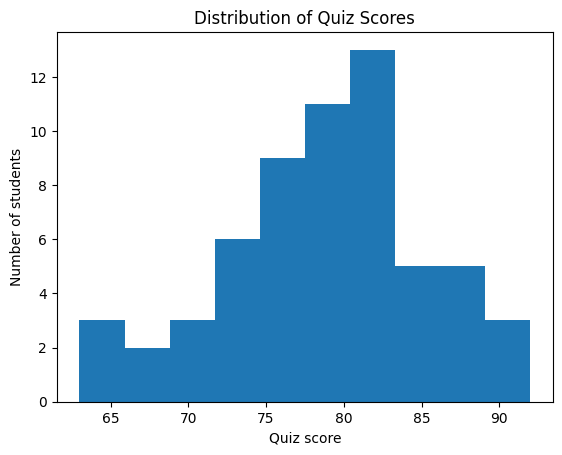

In [4]:
# 輸入成績資料 scores 與 bins=10，用 plt.hist() 畫出分成 10 個區間的直方圖
scores = df["quiz_score"].dropna()
plt.hist(scores, bins=10)
plt.title("Distribution of Quiz Scores")
plt.xlabel("Quiz score")
plt.ylabel("Number of students")
plt.show()
# plt.show() 用來把設定好標題跟座標軸的直方圖正式顯示在畫面上


### 驗證、解釋與延伸 4.2

**延伸練習的預測與驗證**預測改 `bins=5` 後圖上只會有 5 根比較寬的柱子，但資料總筆數一樣是 60。實際執行後確認柱子變 5 根，資料筆數也維持 60。

**AI 求助提示詞：**
> 請引導我完成這個延伸練習：將分箱數改成 5，觀察圖形差異並核對資料筆數不變。 目前資料表名稱為 df。請分步解釋程式，建議我如何檢查輸出，不要捏造結果；如果需要使用前面建立的變數，請指出其前置步驟。


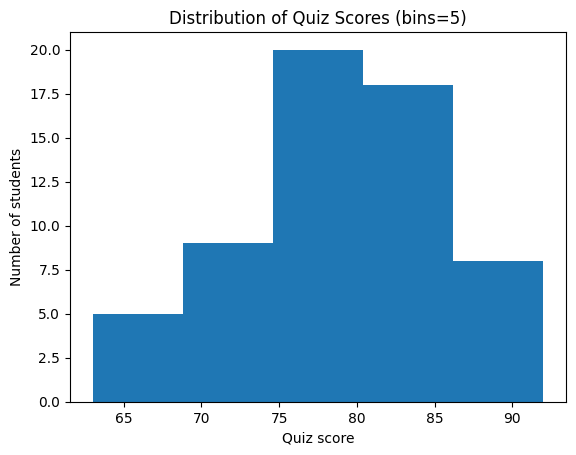

有效資料筆數： 60


In [5]:
# 改用 bins=5 畫直方圖，並印出 len(scores) 確認資料總筆數不變
plt.hist(scores, bins=5)
plt.title("Distribution of Quiz Scores (bins=5)")
plt.xlabel("Quiz score")
plt.ylabel("Number of students")
plt.show()
print("有效資料筆數：", len(scores))


## 4.3 盒鬚圖
盒體描述四分位範圍，線條和點幫助觀察分散與可能離群值；離群並不自動等於錯誤。

### 學生練習 4.3：完成程式與註解

**我的預測**盒鬚圖最上方會出現一個單獨的圓點在 15.0 的位置，最大值會印出 15.0。

**AI 求助提示詞（可直接複製）：**
> 我是 Python 初學者，正在完成資料分析任務 4.3。我的資料表叫 df，請教我如何補上選取螢幕時間並移除缺失值的運算。 請先說明使用的 pandas 或 matplotlib 語法和每個參數，再給我可替換 `___` 的一小段程式；不要假設我的執行結果。請提供一個核對方法，並提醒我如何用自己的話撰寫註解。


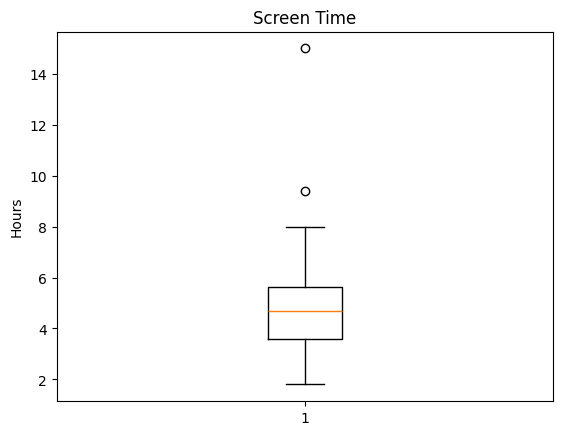

最大值： 15.0


In [6]:
# 輸入 screen_time_hours 欄位，用 dropna() 去掉空值後存給 screen_values
screen_values = df["screen_time_hours"].dropna()
plt.boxplot(screen_values)
plt.title("Screen Time")
plt.ylabel("Hours")
plt.show()
print("最大值：", screen_values.max())
# plt.boxplot() 根據數值分布畫出四分位數盒子跟離群值圓點


### 驗證、解釋與延伸 4.3

**延伸練習的預測與驗證**預測 `study_hours` 範圍在 0.5～6 之間，畫出來不會有像 15.0 那樣誇張的離群點，最大值不超過 6.0。實際執行後確認圖形分布集中，最大值在 6.0 以內。

**AI 求助提示詞：**
> 請引導我完成這個延伸練習：改畫 study_hours 的盒鬚圖，並顯示最大值。 目前資料表名稱為 df。請分步解釋程式，建議我如何檢查輸出，不要捏造結果；如果需要使用前面建立的變數，請指出其前置步驟。


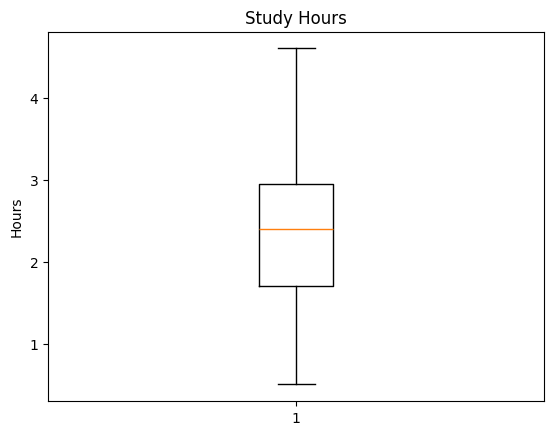

讀書時間最大值： 4.6


In [7]:
# 取出 study_hours 並移除缺失值，畫出盒鬚圖後印出最大值
study_values = df["study_hours"].dropna()
plt.boxplot(study_values)
plt.title("Study Hours")
plt.ylabel("Hours")
plt.show()
print("讀書時間最大值：", study_values.max())


## 任務交付與 AI 使用紀錄

- 使用的 AI 提示詞：用講義給的 4.1～4.3 提示詞查 `.median()`、`plt.hist()` 跟 `plt.boxplot()` 的寫法。
- AI 建議中我修改或拒絕的一處及原因：把 AI 原本寫得太長太制式的註解精簡掉，改用比較口語、直接寫輸入／處理／輸出的短句。
- 遇到的錯誤或疑問、修正與驗證方式：一開始疑問為什麼畫圖前都要先寫 `.dropna()`，查證後知道 matplotlib 遇到 NaN 可能會畫不出來或跳警告，加上 `.dropna()` 後圖表就順利顯示了。
- 本任務一項有數據支持的發現及對應儲存格：4.1 節 `sleep_hours` 的 `count` 顯示 `58.0`（少於總筆數 60），4.3 節盒鬚圖也清楚顯示螢幕時間有一個最大值 `15.0` 的離群點。
- 一項資料或推論限制：圖表標題與座標軸若直接打中文在 Colab 預設環境容易變成方框亂碼，所以維持英文標籤；且這份資料是模擬數據，圖形分布不能代表真實學生。

**交付前檢核：** 已填完程式空格與註解；已填寫預測、驗證、解釋與延伸；已由上到下執行並確認圖表和數字與文字一致。
